# Snack-Segmentierung


In [ ]:
from datetime import datetime
from pathlib import Path
import json

import cv2
import matplotlib.pyplot as plt
import torch
from IPython.display import Image as NotebookImage, display
import yaml
from PIL import Image, ImageDraw
from ultralytics import YOLO

ROOT = Path.cwd()
DATA = ROOT / "data/snack_segmentation"
DATASET = DATA / "dataset"
WEIGHTS = ROOT / "models/snack_segmentation_yolo11n.pt"
SPLITS = ("train", "val", "test")
CLASSES = ["Bounty", "Snickers"]
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"

if not DATASET.is_dir() or not WEIGHTS.is_file():
    raise FileNotFoundError(f"Projektordner öffnen. Erwartet: {DATASET} und {WEIGHTS}")
if DEVICE == "cpu":
    torch.set_num_threads(4)

print(f"Gerät: {DEVICE}")
print(f"Modell: {WEIGHTS.name}")

# Fotos beschriften und Datensatz vorbereiten

train: 15 Bilder
val: 5 Bilder
test: 5 Bilder


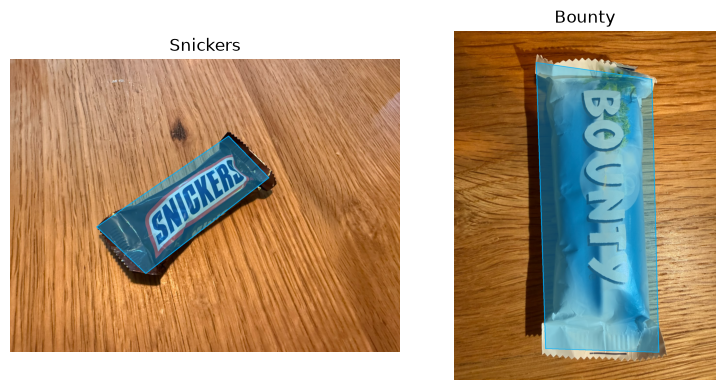

In [2]:
photos = {
    split: sorted((DATASET / "images" / split).glob("*.jpeg")) for split in SPLITS
}
for split, images in photos.items():
    print(f"{split}: {len(images)} Bilder")

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, photo in zip(axes, photos["train"][:2]):
    with Image.open(photo) as image:
        annotated = image.convert("RGB")
    width, height = annotated.size
    draw = ImageDraw.Draw(annotated, "RGBA")
    label_file = DATASET / "labels" / "train" / photo.with_suffix(".txt").name
    labels = []
    for line in label_file.read_text().splitlines():
        class_id, *coordinates = line.split()
        x_coords = coordinates[::2]
        y_coords = coordinates[1::2]
        points = [(float(x) * width, float(y) * height) for x, y in zip(x_coords, y_coords)]
        draw.polygon(points, fill=(0, 176, 255, 100), outline=(0, 176, 255, 255), width=4)
        labels.append(CLASSES[int(class_id)])

    ax.imshow(annotated)
    ax.set_title(", ".join(labels))
    ax.axis("off")
plt.tight_layout()
plt.show()

# YOLO11n-seg laden und optional weitertrainieren


In [ ]:
TRAIN = False
EPOCHS = 3
IMAGE_SIZE = 512

model = YOLO(str(WEIGHTS), task="segment")

if TRAIN:
    run = ROOT / "runs/snack_segmentation" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    run.mkdir(parents=True)
    config = {
        "path": str(DATASET),
        "train": "images/train",
        "val": "images/val",
        "test": "images/test",
        "names": CLASSES,
        "channels": 3,
    }
    dataset_config = run / "data.yaml"
    dataset_config.write_text(yaml.safe_dump(config, sort_keys=False), encoding="utf-8")
    model.train(
        data=str(dataset_config), epochs=EPOCHS, batch=4, imgsz=IMAGE_SIZE,
        device=DEVICE, workers=0, project=str(run), name="train",
        optimizer="AdamW", lr0=0.0001, mosaic=0.0,
        plots=True, seed=42, amp=False,
    )
    trained_weights = Path(model.trainer.best)
    model = YOLO(str(trained_weights), task="segment")
    print(f"Gespeichert: {trained_weights.relative_to(ROOT)}")

# Ergebnisse des mitgelieferten Modells

Masken-mAP50: 99.5%
Masken-mAP50–95: 83.1%


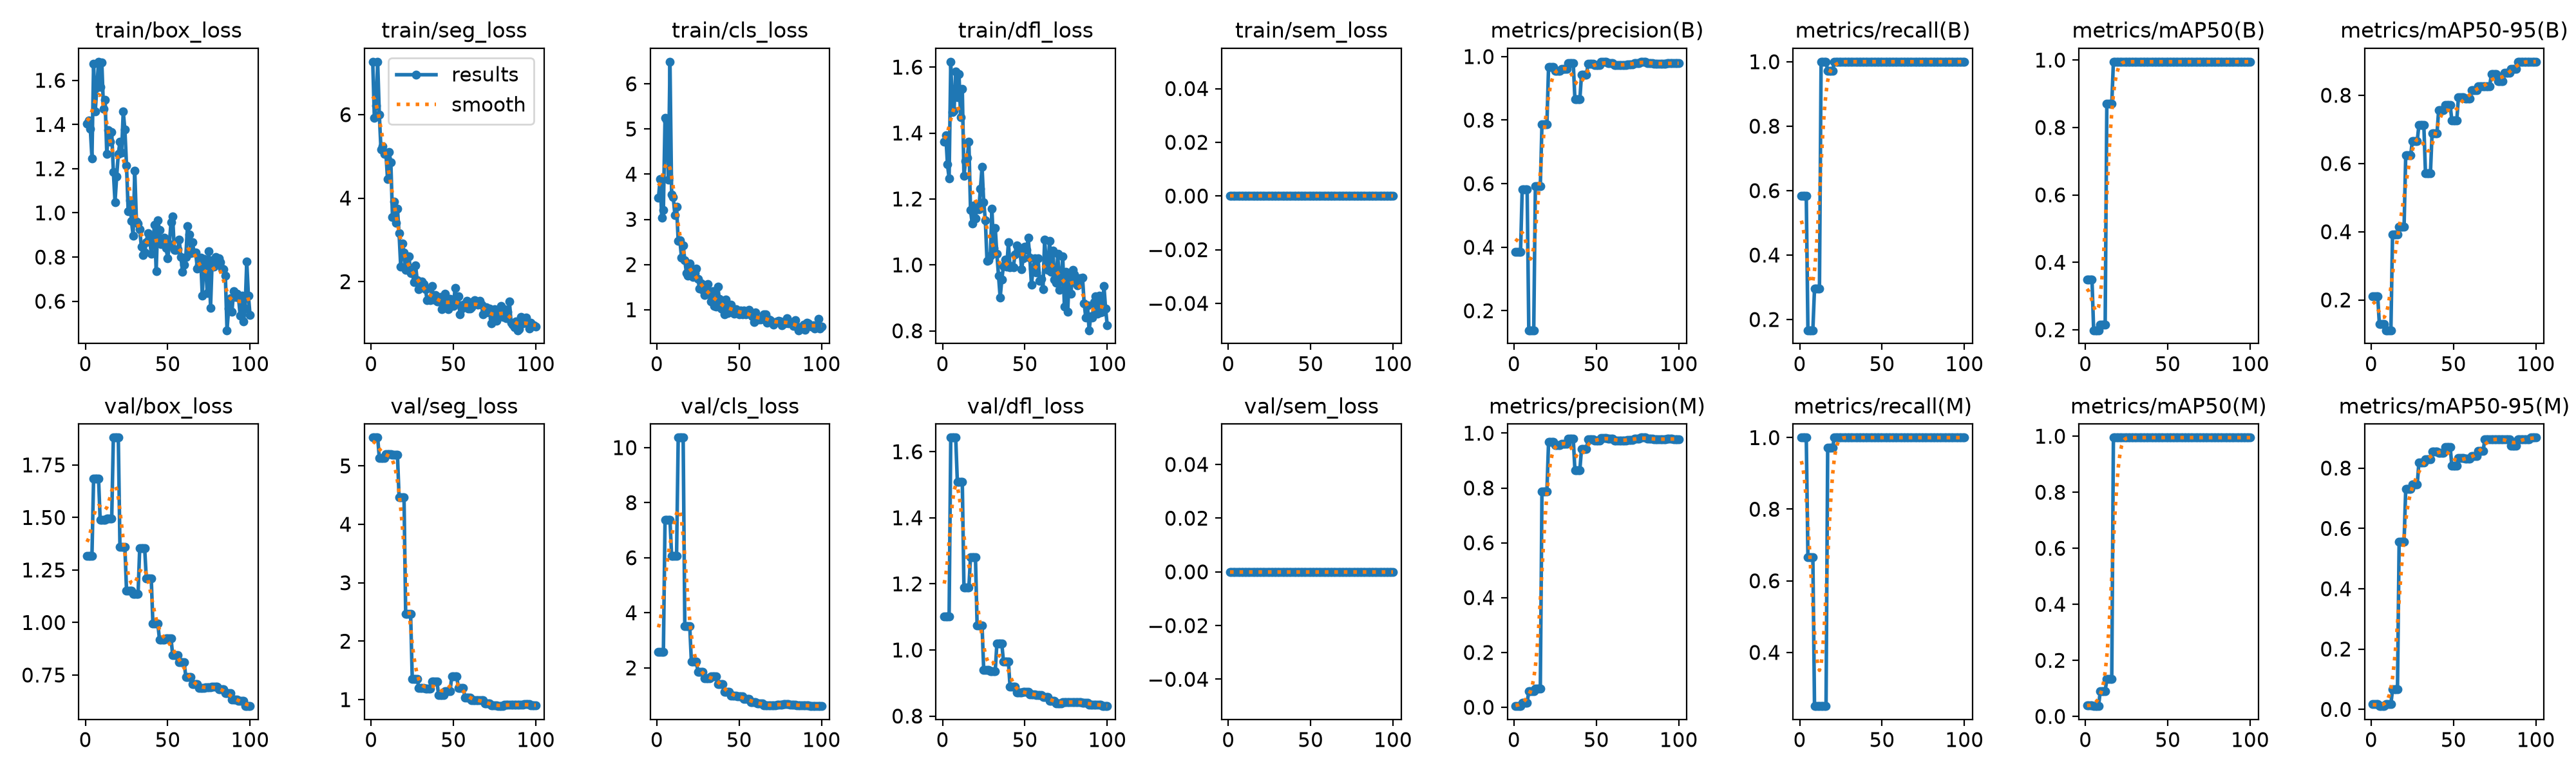

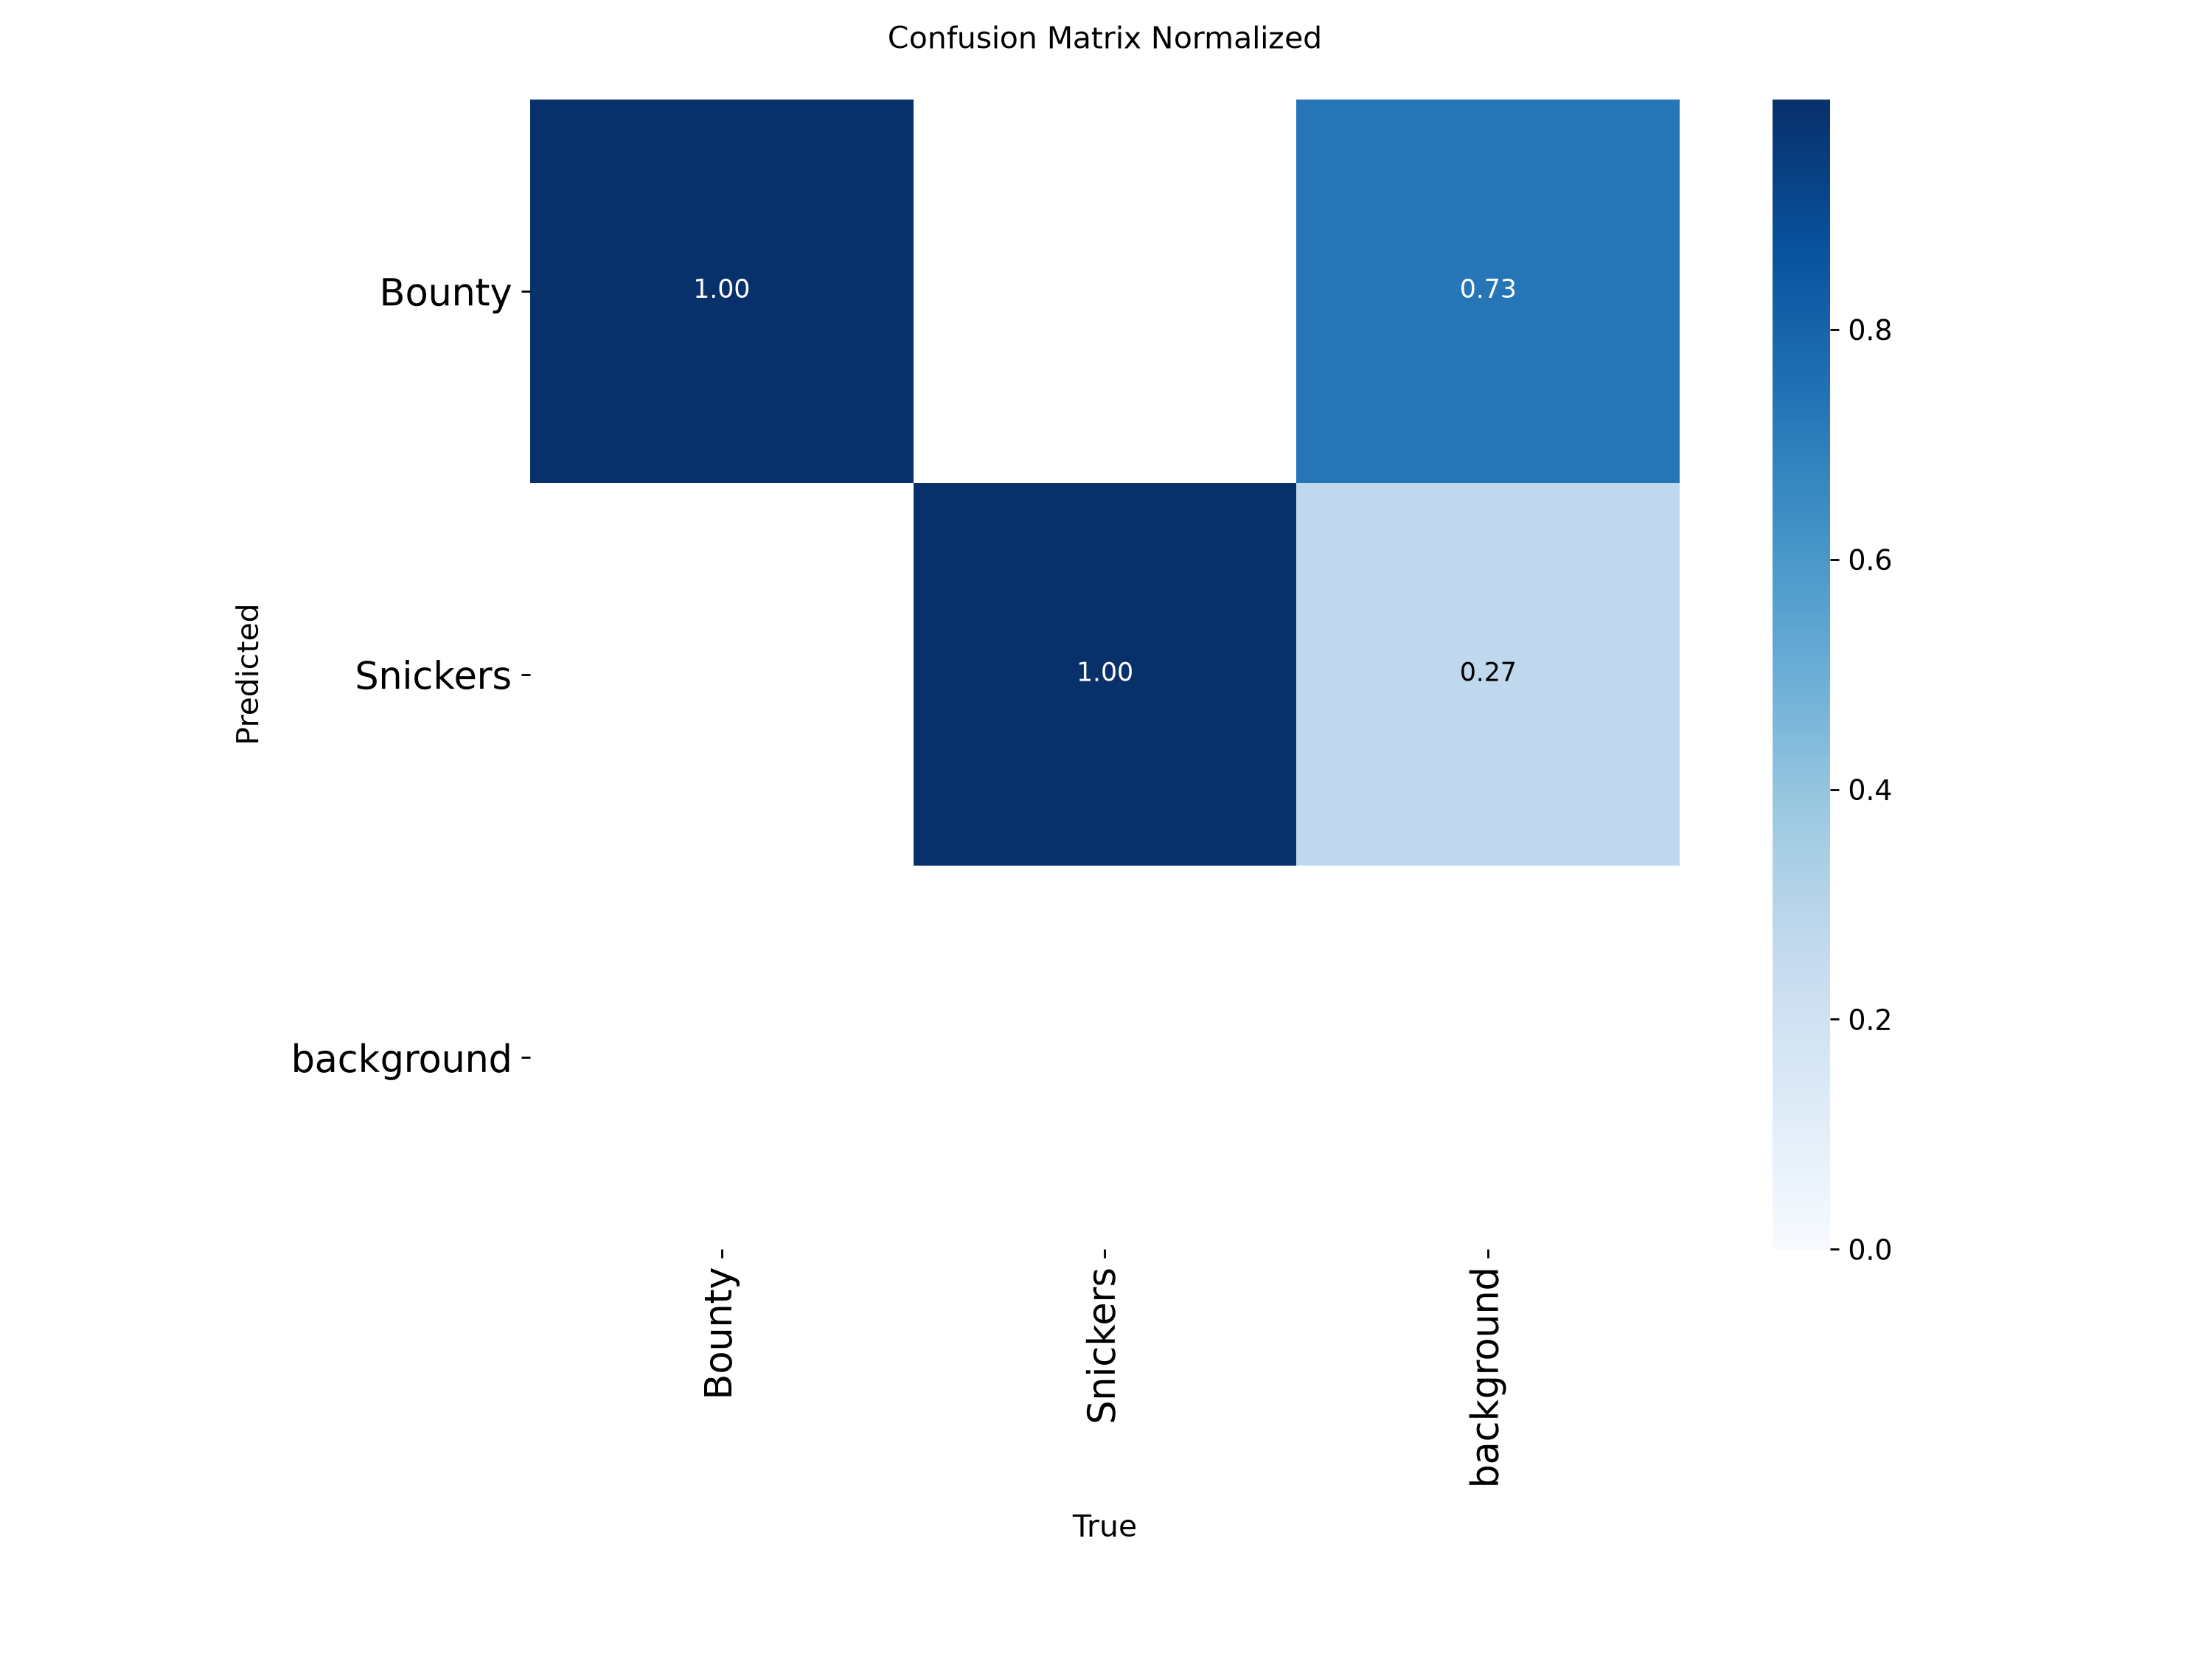

In [4]:
results = DATA / "results"
test = json.loads((results / "metrics.json").read_text())["test"]
print(f"Masken-mAP50: {test['metrics/mAP50(M)']:.1%}")
print(f"Masken-mAP50–95: {test['metrics/mAP50-95(M)']:.1%}")

for filename in ("results.png", "confusion_matrix_normalized.png"):
    display(NotebookImage(filename=str(results / filename), width=750))

# Testbilder segmentieren


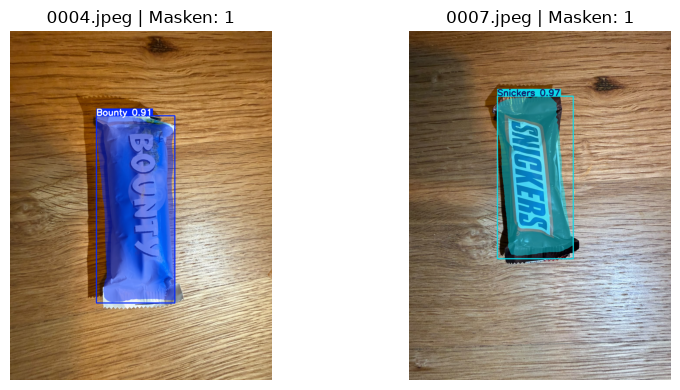

In [5]:
CONFIDENCE = 0.25


def segment(frame):
    return model.predict(
        frame, imgsz=IMAGE_SIZE, conf=CONFIDENCE, device=DEVICE,
        retina_masks=True, verbose=False,
    )[0]


fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, photo in zip(axes, photos["test"][:2]):
    result = segment(str(photo))
    count = len(result.masks) if result.masks is not None else 0
    ax.imshow(cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{photo.name} | Masken: {count}")
    ax.axis("off")
plt.tight_layout()
plt.show()

# Live-Segmentierung

In [ ]:
USE_CAMERA = True
CAMERA = 0

if USE_CAMERA:
    camera = cv2.VideoCapture(CAMERA)
    window = "Snack-Segmentierung | Q / Esc"
    try:
        if not camera.isOpened():
            raise RuntimeError(f"Kamera {CAMERA} lässt sich nicht öffnen.")

        while True:
            ok, frame = camera.read()
            if not ok:
                raise RuntimeError("Die Kamera liefert kein Bild.")

            result = segment(frame)
            frame = result.plot()

            cv2.imshow(window, frame)
            if cv2.waitKey(1) & 0xFF in (ord("q"), 27):
                break
            if cv2.getWindowProperty(window, cv2.WND_PROP_VISIBLE) < 1:
                break
    finally:
        camera.release()
        cv2.destroyAllWindows()